In [1]:

import tensorflow as tf

# Required by Alibi's legacy Counterfactual implementation
tf.compat.v1.disable_v2_behavior()

import numpy as np
import matplotlib.pyplot as plt
from alibi.explainers import Counterfactual

print("TensorFlow:", tf.__version__)
print("Eager execution:", tf.executing_eagerly())


Instructions for updating:
non-resource variables are not supported in the long term


/Users/emanuelepasquini/.pyenv/versions/XAIalibi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.14.1
Eager execution: False


11490434/11490434 [==============================] - 2s 0us/step
Train: (60000, 28, 28, 1)
Test: (10000, 28, 28, 1)


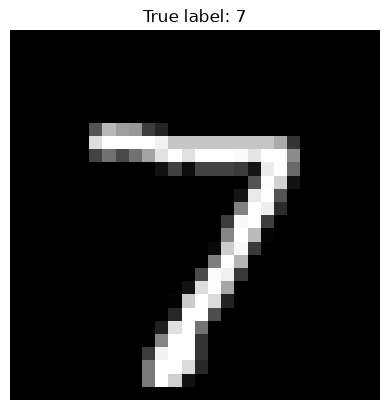

In [2]:

# Load MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to [-0.5, 0.5]
x_train = x_train.astype("float32") / 255.0 - 0.5
x_test = x_test.astype("float32") / 255.0 - 0.5

# Add channel dimension
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Train:", x_train.shape)
print("Test:", x_test.shape)

plt.imshow(x_test[0, :, :, 0], cmap="gray")
plt.title(f"True label: {y_test[0]}")
plt.axis("off")
plt.show()


In [3]:

from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(64, 2, padding="same", activation="relu")(inputs)
x = layers.MaxPooling2D(2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Conv2D(32, 2, padding="same", activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(10, activation="softmax")(x)

cnn = Model(inputs, outputs)

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.fit(
    x_train, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.1
)

print("Test accuracy:", cnn.evaluate(x_test, y_test, verbose=0)[1])


Train on 54000 samples, validate on 6000 samples
Epoch 1/3
   64/54000 [..............................] - ETA: 1:38 - loss: 2.3149 - acc: 0.0938

2026-11-24 15:37:59.665058: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:382] MLIR V1 optimization pass is not enabled
2026-11-24 15:37:59.706360: W tensorflow/c/c_api.cc:305] Operation '{name:'training/Adam/dense_1/bias/v/Assign' id:481 op device:{requested: '', assigned: ''} def:{{{node training/Adam/dense_1/bias/v/Assign}} = AssignVariableOp[_has_manual_control_dependencies=true, dtype=DT_FLOAT, validate_shape=false](training/Adam/dense_1/bias/v, training/Adam/dense_1/bias/v/Initializer/zeros)}}' was changed by setting attribute after it was run by a session. This mutation will have no effect, and will trigger an error in the future. Either don't modify nodes after running them or create a new session.


53696/54000 [============================>.] - ETA: 0s - loss: 0.3390 - acc: 0.8912

/Users/emanuelepasquini/.pyenv/versions/XAIalibi/lib/python3.11/site-packages/keras/src/engine/training_v1.py:2335: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates = self.state_updates
2026-11-24 15:38:06.814258: W tensorflow/c/c_api.cc:305] Operation '{name:'loss/mul' id:198 op device:{requested: '', assigned: ''} def:{{{node loss/mul}} = Mul[T=DT_FLOAT, _has_manual_control_dependencies=true](loss/mul/x, loss/dense_1_loss/value)}}' was changed by setting attribute after it was run by a session. This mutation will have no effect, and will trigger an error in the future. Either don't modify nodes after running them or create a new session.


54000/54000 [==============================] - 7s 136us/sample - loss: 0.3380 - acc: 0.8914 - val_loss: 0.0681 - val_acc: 0.9802
Epoch 2/3
54000/54000 [==============================] - 7s 130us/sample - loss: 0.1234 - acc: 0.9625 - val_loss: 0.0472 - val_acc: 0.9867
Epoch 3/3
54000/54000 [==============================] - 6s 116us/sample - loss: 0.0944 - acc: 0.9705 - val_loss: 0.0385 - val_acc: 0.9902
Test accuracy: 0.9878


Original prediction: 7


2026-11-24 15:45:08.345516: W tensorflow/c/c_api.cc:305] Operation '{name:'cf_search_5/beta2_power/Assign' id:2219 op device:{requested: '', assigned: ''} def:{{{node cf_search_5/beta2_power/Assign}} = Assign[T=DT_FLOAT, _class=["loc:@cf_search/counterfactual"], _has_manual_control_dependencies=true, use_locking=true, validate_shape=true](cf_search_5/beta2_power, cf_search_5/beta2_power/initial_value)}}' was changed by setting attribute after it was run by a session. This mutation will have no effect, and will trigger an error in the future. Either don't modify nodes after running them or create a new session.


Counterfactual prediction: 9
Probabilities: [[4.2591147e-08 2.6077789e-08 9.4921965e-08 9.9248544e-04 3.2434611e-05
  2.5196536e-05 6.0058619e-10 8.2441382e-03 2.2042160e-04 9.9048513e-01]]


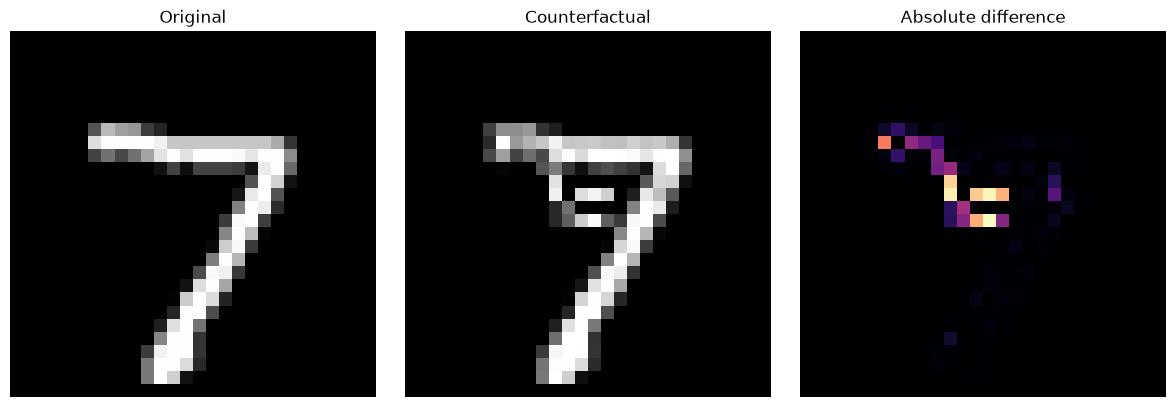

In [11]:

# Original MNIST image
X = x_test[0:1]

print("Original prediction:", cnn.predict(X, verbose=0).argmax())

# Initialize Alibi explainer
cf = Counterfactual(
    cnn,
    shape=(1, 28, 28, 1),
    target_proba=1.0,
    tol=0.01,
    target_class=9,     # "other"
    max_iter=1000,
    lam_init=0.1,
    max_lam_steps=10,
    learning_rate_init=0.1,
    feature_range=(-0.5, 0.5)
)

# Generate counterfactual
explanation = cf.explain(X)

if explanation.cf is None:
    print("No counterfactual found.")
else:
    X_cf = explanation.cf["X"]

    print("Counterfactual prediction:", explanation.cf["class"])
    print("Probabilities:", explanation.cf["proba"])

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(X[0, :, :, 0], cmap="gray")
    axes[0].set_title("Original")

    axes[1].imshow(X_cf[0, :, :, 0], cmap="gray")
    axes[1].set_title("Counterfactual")

    difference = np.abs(X_cf[0, :, :, 0] - X[0, :, :, 0])
    axes[2].imshow(difference, cmap="magma")
    axes[2].set_title("Absolute difference")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [12]:

# Quantitative evaluation of the counterfactual

X_cf = explanation.cf["X"]

delta = X_cf - X
abs_delta = np.abs(delta)

print("Original prediction:", cnn.predict(X, verbose=0).argmax())
print("Counterfactual prediction:", cnn.predict(X_cf, verbose=0).argmax())

print("L1 distance:", np.sum(abs_delta))
print("L2 distance:", np.linalg.norm(delta))
print("L-infinity distance:", np.max(abs_delta))
print("Mean absolute change:", np.mean(abs_delta))

# Fraction of pixels modified by more than 0.01
changed = abs_delta > 0.01

print("Pixels changed (> 0.01):", np.sum(changed))
print("Percentage changed:", round(100 * np.mean(changed), 2), "%")


Original prediction: 7
Counterfactual prediction: 9
L1 distance: 12.771759
L2 distance: 2.7382362
L-infinity distance: 0.97267383
Mean absolute change: 0.016290508
Pixels changed (> 0.01): 71
Percentage changed: 9.06 %
